<div style="background:#132c46;color:#ffffff;padding:26px;border-radius:8px">
<p style="color:#90c9f9;letter-spacing:2px">DATHEON · MACHINE LEARNING & DATA SCIENCE</p>
<h1 style="color:#ffffff">Iris Classification</h1>
<p>Task 01 · Multi-Class Benchmark Classification Pipeline</p>
<p>Arafat Rahman · Application ID: DT-2026-JTNGO</p>
</div>

## 01 · Project Title and Objective

Compare Logistic Regression and a Decision Tree on the same held-out Iris samples.
The workflow covers data quality, exploration, leakage-free scaling, classification
metrics and error analysis. Only Task 1 is included.

## 02 · Dataset Description

The [Datheon Task Pack](https://www.datheon.in/training/catalog/machine-learning-and-data-science-internship)
links to the [Seaborn Iris CSV](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv).
It contains 150 flowers, four measurements in centimetres and three species:
setosa, versicolor and virginica. Each species has 50 samples.

| Feature | Measurement |
|:--|:--|
| `sepal_length`, `sepal_width` | Sepal dimensions (cm) |
| `petal_length`, `petal_width` | Petal dimensions (cm) |
| `species` | Classification target |

The source is downloaded into memory; no temporary dataset is committed.

## 03 · Import Libraries and Reproducibility Settings

A fixed seed, explicit class order and consistent plotting style keep the comparison reproducible. Run from the repository root or the Task 1 folder.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO
import hashlib
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.utils.validation import check_is_fitted

SEED = 42
CLASSES = ['setosa', 'versicolor', 'virginica']
FEATURES = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
COLORS = dict(zip(CLASSES, ['#2864a5', '#d18418', '#9866a8']))
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220,
                     'axes.titleweight': 'bold', 'axes.spines.top': False,
                     'axes.spines.right': False, 'grid.alpha': 0.25})
pd.set_option('display.precision', 4)

cwd = Path.cwd()
if cwd.name == 'Task_01_Classification':
    TASK_DIR = cwd
elif (cwd / 'Task_01_Classification').is_dir():
    TASK_DIR = cwd / 'Task_01_Classification'
else:
    raise RuntimeError('Run from the repository root or Task_01_Classification folder.')
FIGURES = TASK_DIR / 'figures'
RESULTS = TASK_DIR / 'results'
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

def save_figure(fig, filename):
    fig.savefig(FIGURES / filename, bbox_inches='tight', facecolor='white')

print('Python:', platform.python_version())
display(pd.Series({name: version(name) for name in
                   ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'seaborn']},
                  name='Version').to_frame())

Python: 3.12.10


,Version
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2


## 04 · Dataset Loading

Load the required CSV directly. A failed download stops execution rather than silently substituting another dataset. The SHA-256 fingerprint records the exact source bytes used.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
try:
    with urlopen(DATA_URL, timeout=30) as response:
        source_bytes = response.read()
except Exception as exc:
    raise RuntimeError('Required Iris CSV download failed; no substitute was used.') from exc
source_sha256 = hashlib.sha256(source_bytes).hexdigest()
iris = pd.read_csv(BytesIO(source_bytes))
assert iris.shape == (150, 5), f'Unexpected shape: {iris.shape}'
assert iris.columns.tolist() == FEATURES + ['species']
assert set(iris['species']) == set(CLASSES)
assert iris.isna().sum().sum() == 0, 'Missing values require review before training.'
assert all(pd.api.types.is_numeric_dtype(iris[f]) for f in FEATURES)
assert np.isfinite(iris[FEATURES].to_numpy()).all()
assert iris['species'].value_counts().reindex(CLASSES).eq(50).all()
print('Validated shape:', iris.shape)
print('Source SHA-256:', source_sha256)
display(iris.head())

Validated shape: (150, 5)
Source SHA-256: 9cc1c345c71bcc9b486b74cbf6063fa66f4bb5e0f603a4b3c3471ec2e5e8e355


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 05 · Data Quality Assessment

Check types, missingness, class counts and repeated rows. Matching measurements are retained to preserve the supplied benchmark; identical measurements alone do not prove a recording error. Split overlap is checked explicitly below.

In [3]:
quality = pd.DataFrame({'dtype': iris.dtypes.astype(str),
                        'missing': iris.isna().sum(),
                        'unique_values': iris.nunique()})
display(quality)
duplicate_count = int(iris.duplicated().sum())
print(f'Duplicate rows beyond the first occurrence: {duplicate_count}')
display(iris.loc[iris.duplicated(keep=False)])
display(iris['species'].value_counts().reindex(CLASSES).rename('samples').to_frame())

,dtype,missing,unique_values
sepal_length,float64,0,35
sepal_width,float64,0,23
petal_length,float64,0,43
petal_width,float64,0,22
species,str,0,3


Duplicate rows beyond the first occurrence: 1


,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


,samples
species,
setosa,50
versicolor,50
virginica,50


## 06 · Exploratory Data Analysis

Summarize measurement ranges and class means. This is descriptive exploration of the benchmark; the four model features and model settings are fixed in advance, with no test-driven tuning.

In [4]:
display(iris[FEATURES].describe().round(2))
display(iris.groupby('species')[FEATURES].mean().reindex(CLASSES).round(2))

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


## 07 · Class Distribution Visualization

Show the number of observations per species. Equal class sizes make accuracy interpretable alongside the macro-averaged metrics.

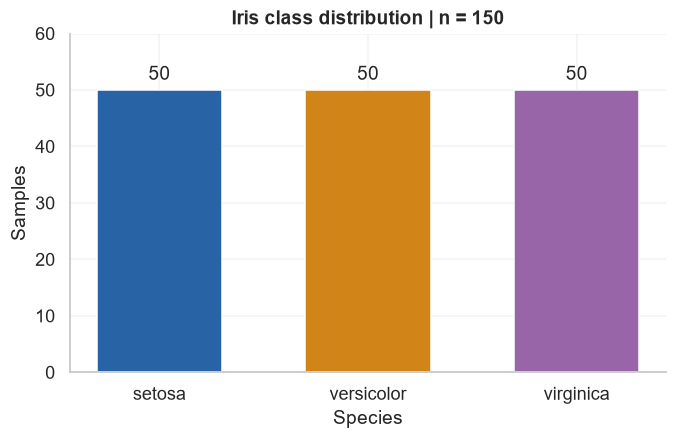

In [5]:
counts = iris['species'].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color=[COLORS[c] for c in CLASSES], width=0.6)
ax.bar_label(bars, padding=4)
ax.set(title=f'Iris class distribution | n = {len(iris)}', xlabel='Species', ylabel='Samples', ylim=(0, 60))
save_figure(fig, 'class_distribution.png')
plt.show()

## 08 · Feature Distribution and Pairplot

Diagonal histograms show individual feature distributions; scatterplots show pairwise relationships. Different markers distinguish species as well as colour.

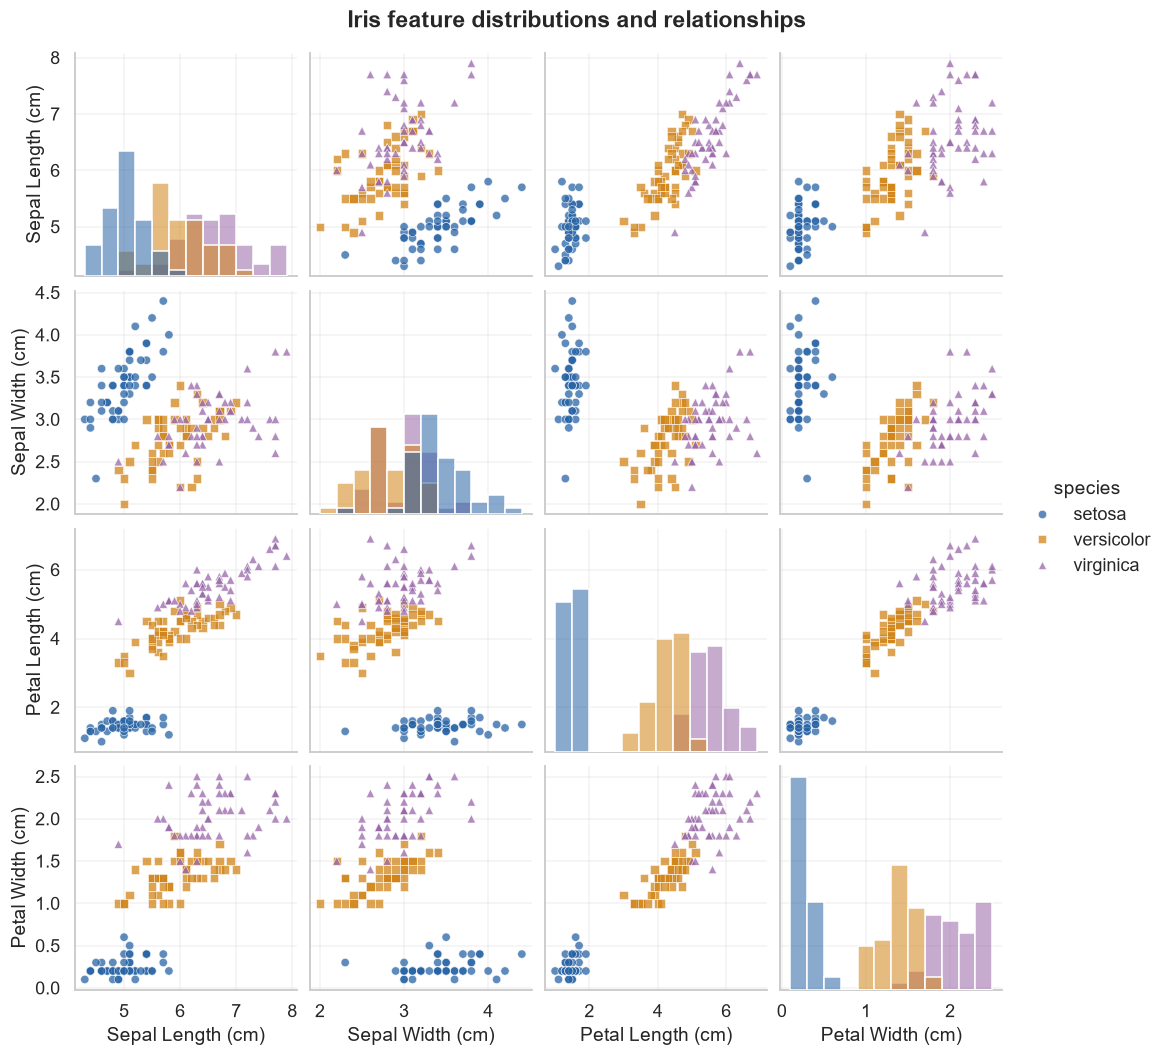

In [6]:
labels = {f: f.replace('_', ' ').title() + ' (cm)' for f in FEATURES}
pairplot = sns.pairplot(iris.rename(columns=labels), vars=list(labels.values()),
                       hue='species', hue_order=CLASSES, palette=COLORS,
                       markers=['o', 's', '^'], diag_kind='hist', height=2.35,
                       plot_kws={'alpha': 0.75, 's': 30},
                       diag_kws={'alpha': 0.55, 'bins': 12})
pairplot.figure.suptitle('Iris feature distributions and relationships', y=1.02, weight='bold')
save_figure(pairplot.figure, 'iris_pairplot.png')
plt.show()

Petal measurements separate setosa clearly in these plots. Versicolor and virginica overlap more, so visual separation alone does not establish classification performance.

## 09 · Feature and Target Separation

Use all four numeric measurements as predictors. Species remains a categorical target and is never included in the feature matrix.

In [7]:
X = iris[FEATURES].copy()
y = iris['species'].copy()
assert 'species' not in X.columns
print(f'Features: {X.shape}; target: {y.shape}')

Features: (150, 4); target: (150,)


## 10 · Stratified 80/20 Train-Test Split

Both models use exactly the same 120 training and 30 test observations. Stratification preserves the class proportions; the test set is reserved for evaluation.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
assert len(X_train) == 120 and len(X_test) == 30
assert set(X_train.index).isdisjoint(X_test.index)
split_counts = pd.DataFrame({'Train': y_train.value_counts(),
                             'Test': y_test.value_counts()}).reindex(CLASSES)
assert split_counts['Train'].eq(40).all() and split_counts['Test'].eq(10).all()
display(split_counts)
train_vectors = set(map(tuple, X_train.to_numpy()))
test_vectors = set(map(tuple, X_test.to_numpy()))
overlap = len(train_vectors & test_vectors)
print('Identical feature vectors shared across train and test:', overlap)
assert overlap == 0, 'Repeated feature vectors cross the split; review leakage risk.'

,Train,Test
species,,
setosa,40,10
versicolor,40,10
virginica,40,10


Identical feature vectors shared across train and test: 0


## 11 · Feature Scaling

Fit `StandardScaler` on training features only, then transform both partitions. The Decision Tree uses raw measurements because its threshold splits do not require standardization.

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
assert scaler.n_samples_seen_ == len(X_train)
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy())
np.testing.assert_allclose(X_train_scaled.mean(axis=0), 0, atol=1e-12)
display(pd.DataFrame({'training_mean': scaler.mean_,
                      'training_scale': scaler.scale_}, index=FEATURES))

,training_mean,training_scale
sepal_length,5.8417,0.8374
sepal_width,3.0483,0.4467
petal_length,3.7700,1.7611
petal_width,1.2050,0.7595


## 12 · Logistic Regression Training

Train the specified linear classifier on standardized training features. No hyperparameter search is performed.

In [10]:
logistic_regression = LogisticRegression(max_iter=1000, random_state=SEED)
logistic_regression.fit(X_train_scaled, y_train)
check_is_fitted(logistic_regression)
logistic_predictions = logistic_regression.predict(X_test_scaled)
print('Fitted Logistic Regression with', logistic_regression.n_features_in_, 'features.')

Fitted Logistic Regression with 4 features.


## 13 · Decision Tree Training

Train the specified tree on the same observations with unscaled features. The unchanged test split keeps the comparison consistent.

In [11]:
decision_tree = DecisionTreeClassifier(random_state=SEED)
decision_tree.fit(X_train, y_train)
check_is_fitted(decision_tree)
tree_predictions = decision_tree.predict(X_test)
print('Fitted Decision Tree with', decision_tree.n_features_in_, 'features.')

Fitted Decision Tree with 4 features.


## 14 · Performance Evaluation

Accuracy measures the proportion of correct predictions. Macro precision, recall and F1 give each species equal weight. All values below are calculated from held-out predictions.

In [12]:
predictions = {'Logistic Regression': logistic_predictions,
               'Decision Tree': tree_predictions}
rows = []
for name, predicted in predictions.items():
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, predicted),
                 'Macro Precision': precision_score(y_test, predicted, average='macro', zero_division=0),
                 'Macro Recall': recall_score(y_test, predicted, average='macro', zero_division=0),
                 'Macro F1': f1_score(y_test, predicted, average='macro', zero_division=0)})
comparison = pd.DataFrame(rows).set_index('Model')
comparison.to_csv(RESULTS / 'model_comparison.csv')
display(comparison.style.format('{:.2%}').set_caption('Four-feature models | 30 held-out samples'))

,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Logistic Regression,93.33%,93.33%,93.33%,93.33%
Decision Tree,93.33%,93.33%,93.33%,93.33%


## 15 · Classification Reports

Per-class precision, recall, F1 and support reveal differences hidden by aggregate scores. Zero-division handling is explicit.

In [13]:
report_sections = []
for name, predicted in predictions.items():
    report = classification_report(y_test, predicted, labels=CLASSES, digits=4, zero_division=0)
    print(f'{name}\n{report}')
    report_sections.append(f'{name}\n{report}')
(RESULTS / 'classification_reports.txt').write_text(
    '\n'.join(report_sections), encoding='utf-8'
)

Logistic Regression
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

Decision Tree
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



795

## 16 · Confusion Matrix Visualization

Rows are true labels and columns are predicted labels. Both matrices use the same class order and colour scale.

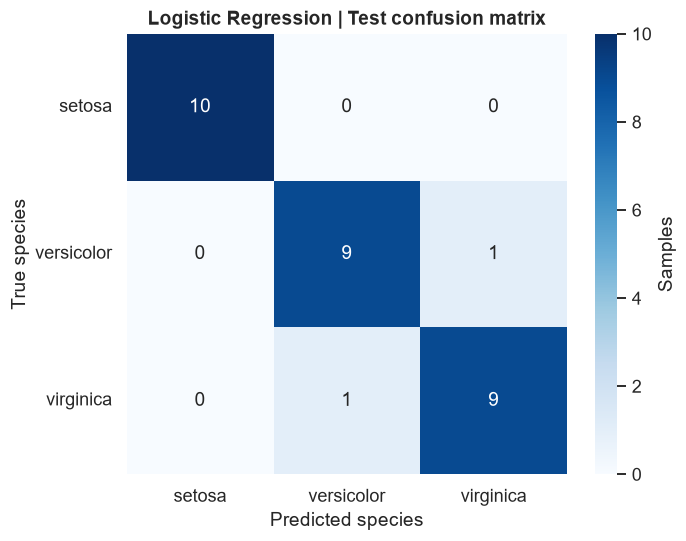

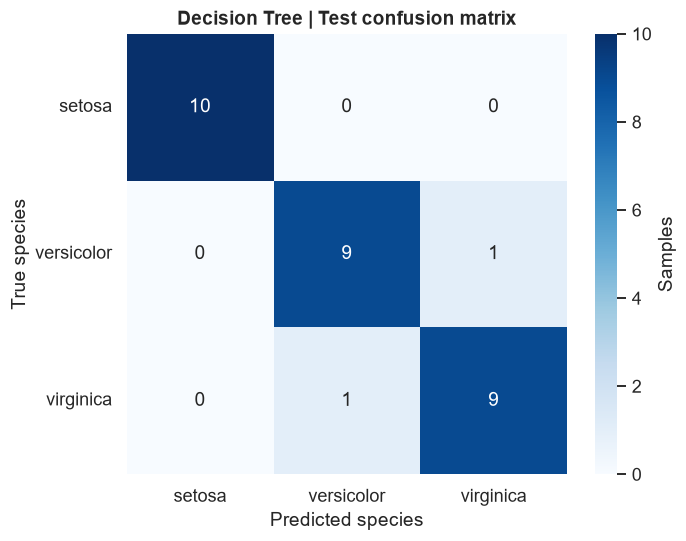

In [14]:
confusion_matrices = {}
for name, predicted in predictions.items():
    matrix = confusion_matrix(y_test, predicted, labels=CLASSES)
    confusion_matrices[name] = matrix
    fig, ax = plt.subplots(figsize=(6.6, 5.2))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', vmin=0, vmax=10,
                xticklabels=CLASSES, yticklabels=CLASSES, square=True,
                cbar_kws={'label': 'Samples'}, ax=ax)
    ax.set(title=f'{name} | Test confusion matrix', xlabel='Predicted species', ylabel='True species')
    ax.tick_params(axis='y', rotation=0)
    filename = 'confusion_matrix_' + name.lower().replace(' ', '_') + '.png'
    save_figure(fig, filename)
    plt.show()

## 17 · Model Comparison

Compare the four-feature models on a common 0–100% scale. Values are shown directly so small differences remain clear without truncating the axis.

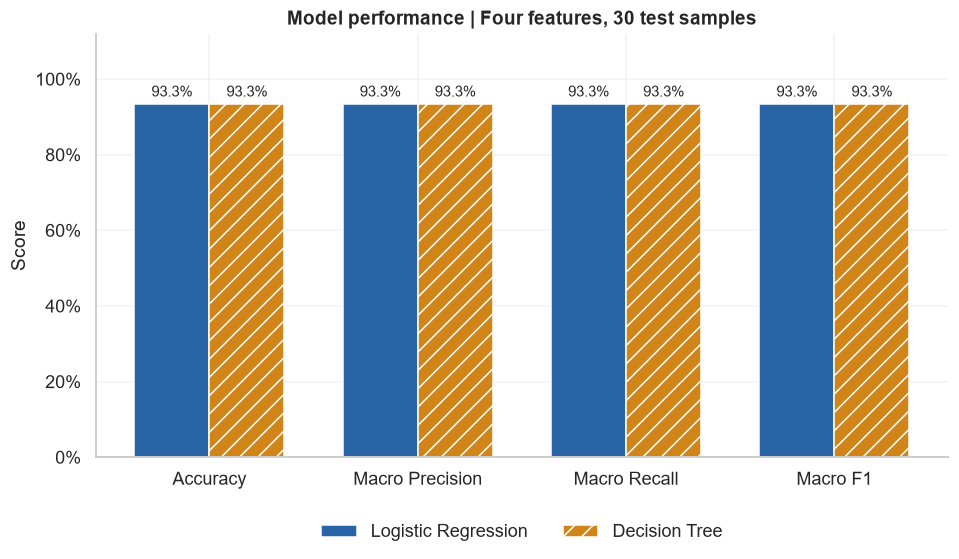

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(comparison.columns))
for i, (name, row) in enumerate(comparison.iterrows()):
    bars = ax.bar(positions + (i - 0.5) * 0.36, row.values, width=0.36,
                  label=name, color=['#2864a5', '#d18418'][i], hatch=['', '//'][i])
    ax.bar_label(bars, labels=[f'{value:.1%}' for value in row], padding=3, fontsize=10)
ax.set_xticks(positions, comparison.columns)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(ylim=(0, 1.12), ylabel='Score', title='Model performance | Four features, 30 test samples')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
save_figure(fig, 'model_comparison.png')
plt.show()

## 18 · Decision Boundary Visualization

<div style="border-left:4px solid #d18418;padding:10px;background:#fff5df;color:#332b20">
Separate illustration models use <b>petal length and petal width only</b>, chosen in advance for an interpretable centimetre-scale view.
They are trained on the original training rows and do not produce the four-feature metrics above.
The plotted points are training samples only.</div>

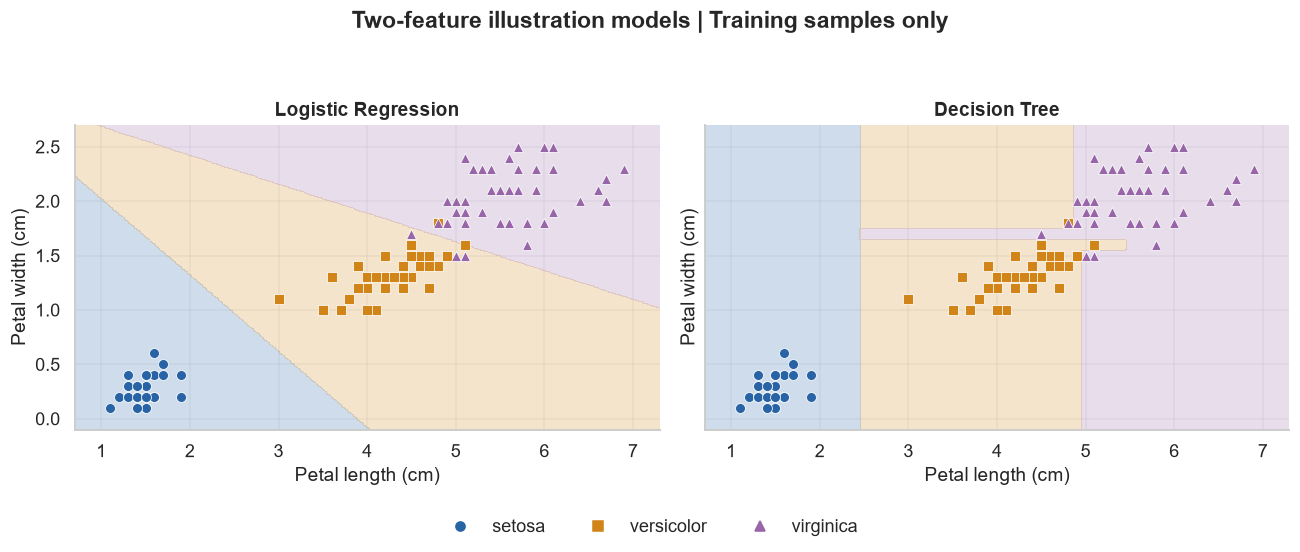

In [16]:
BOUNDARY_FEATURES = ['petal_length', 'petal_width']
X_visual = X_train[BOUNDARY_FEATURES]
visual_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    'Decision Tree': DecisionTreeClassifier(random_state=SEED)
}
class_codes = {name: i for i, name in enumerate(CLASSES)}
cmap = ListedColormap([COLORS[name] for name in CLASSES])
x_grid = np.linspace(X_visual.iloc[:, 0].min() - 0.4, X_visual.iloc[:, 0].max() + 0.4, 300)
y_grid = np.linspace(X_visual.iloc[:, 1].min() - 0.2, X_visual.iloc[:, 1].max() + 0.2, 250)
xx, yy = np.meshgrid(x_grid, y_grid)
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=BOUNDARY_FEATURES)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, visual_models.items()):
    model.fit(X_visual, y_train)
    encoded = np.array([class_codes[label] for label in model.predict(grid)]).reshape(xx.shape)
    ax.contourf(xx, yy, encoded, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap, alpha=0.22)
    for species, marker in zip(CLASSES, ['o', 's', '^']):
        mask = y_train.eq(species)
        ax.scatter(X_visual.loc[mask, 'petal_length'], X_visual.loc[mask, 'petal_width'],
                   color=COLORS[species], marker=marker, edgecolors='white', linewidths=0.5, s=42)
    ax.set(title=name, xlabel='Petal length (cm)', ylabel='Petal width (cm)')
handles = [Line2D([], [], marker=m, linestyle='', color=COLORS[c], label=c)
           for c, m in zip(CLASSES, ['o', 's', '^'])]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False)
fig.suptitle('Two-feature illustration models | Training samples only', weight='bold')
fig.tight_layout(rect=(0, 0.08, 1, 0.93))
save_figure(fig, 'decision_boundaries.png')
plt.show()

## 19 · Error Analysis

List incorrect predictions with original zero-based CSV row indices and all four measurements. These observations describe this split; they are not used to tune either model.

In [17]:
error_counts = {}
for name, predicted in predictions.items():
    errors = X_test.assign(true_class=y_test, predicted_class=predicted)
    errors = errors.loc[errors['true_class'] != errors['predicted_class']].sort_index()
    errors.index.name = 'source_row'
    error_counts[name] = len(errors)
    display(Markdown(f'**{name}: {len(errors)} incorrect predictions out of {len(y_test)}.**'))
    if errors.empty:
        print('No misclassified test examples in this split.')
    else:
        display(errors)

**Logistic Regression: 2 incorrect predictions out of 30.**

,sepal_length,sepal_width,petal_length,petal_width,true_class,predicted_class
source_row,,,,,,
77,6.7,3.0,5.0,1.7,versicolor,virginica
134,6.1,2.6,5.6,1.4,virginica,versicolor


**Decision Tree: 2 incorrect predictions out of 30.**

,sepal_length,sepal_width,petal_length,petal_width,true_class,predicted_class
source_row,,,,,,
77,6.7,3.0,5.0,1.7,versicolor,virginica
134,6.1,2.6,5.6,1.4,virginica,versicolor


## 20 · Results Discussion

The comparison below is generated from the saved metric table, rather than manually entered scores.

In [18]:
for name, row in comparison.iterrows():
    display(Markdown(
        f"**{name}** — accuracy **{row['Accuracy']:.2%}**, macro precision "
        f"**{row['Macro Precision']:.2%}**, macro recall **{row['Macro Recall']:.2%}**, "
        f"macro F1 **{row['Macro F1']:.2%}**; {error_counts[name]} test errors."
    ))
if np.allclose(comparison.iloc[0], comparison.iloc[1]):
    finding = 'Both models have identical aggregate scores on this held-out split; there is no observed metric advantage.'
else:
    best_f1 = comparison['Macro F1'].max()
    leaders = comparison.index[np.isclose(comparison['Macro F1'], best_f1)].tolist()
    finding = (' and '.join(leaders) + ' achieved the highest macro F1 on this split. '
               'This observation does not establish general algorithm superiority.')
display(Markdown(finding))

**Logistic Regression** — accuracy **93.33%**, macro precision **93.33%**, macro recall **93.33%**, macro F1 **93.33%**; 2 test errors.

**Decision Tree** — accuracy **93.33%**, macro precision **93.33%**, macro recall **93.33%**, macro F1 **93.33%**; 2 test errors.

Both models have identical aggregate scores on this held-out split; there is no observed metric advantage.

## 21 · Conclusion and Limitations

The required classification workflow is complete: the source is validated, both models use the same stratified split, scaling is fitted on training data only, and results include class-level errors.

- This is a small, balanced benchmark with only 30 test samples. One changed prediction moves accuracy by approximately 3.33 percentage points.
- A single split does not quantify performance variability or establish performance on new populations.
- Matching source rows are retained; the split check confirms that identical feature vectors do not cross the train/test boundary in this run.
- EDA describes the full dataset, but no feature selection or parameter tuning is based on test outcomes.
- Two-feature boundary plots are illustrations, not the evaluated four-feature models.
- The CSV URL follows an upstream branch. The recorded fingerprint helps detect future source changes; rerunning requires internet access.

**Verification:** the checks below independently reconstruct the reported metrics from confusion-matrix counts and confirm that all required artifacts exist.

In [19]:
for name, matrix in confusion_matrices.items():
    true_positive = np.diag(matrix).astype(float)
    precision = np.divide(true_positive, matrix.sum(axis=0), out=np.zeros(3), where=matrix.sum(axis=0) != 0)
    recall = np.divide(true_positive, matrix.sum(axis=1), out=np.zeros(3), where=matrix.sum(axis=1) != 0)
    per_class_f1 = np.divide(2 * precision * recall, precision + recall,
                             out=np.zeros(3), where=(precision + recall) != 0)
    independently_calculated = [true_positive.sum() / matrix.sum(), precision.mean(), recall.mean(), per_class_f1.mean()]
    np.testing.assert_allclose(comparison.loc[name].to_numpy(), independently_calculated)
    assert matrix.sum() == len(y_test)
    assert error_counts[name] == matrix.sum() - np.trace(matrix)
saved = pd.read_csv(RESULTS / 'model_comparison.csv', index_col='Model')
np.testing.assert_allclose(saved.to_numpy(), comparison.to_numpy())
expected_figures = ['iris_pairplot.png', 'class_distribution.png',
                    'confusion_matrix_logistic_regression.png', 'confusion_matrix_decision_tree.png',
                    'model_comparison.png', 'decision_boundaries.png']
for filename in expected_figures:
    assert (FIGURES / filename).is_file() and (FIGURES / filename).stat().st_size > 1000
assert (RESULTS / 'classification_reports.txt').stat().st_size > 0
print('Verification passed: source, split, scaling, fitted models, metrics and all 8 generated artifacts.')

Verification passed: source, split, scaling, fitted models, metrics and all 8 generated artifacts.
